# 01 - Data: loading, cleaning, split and EDA

Dataset: IMDB 50K movie reviews (binary: `positive` / `negative`).

Order matters: clean -> hold out the test pool -> explore **train only**, so nothing about the test set influences model design.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from src.data_utils import load_raw, clean_text, LABELS, PROJECT_ROOT

SEED = 42
CHART_DIR = PROJECT_ROOT / 'results' / 'charts'
CHART_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_colwidth', 300)

## 1. Load raw data

In [2]:
raw = load_raw()
print(raw.shape)
raw.head(3)

(50000, 2)


,text,label
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO....",positive
1,"A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only ""has got all the pola...",positive
2,"I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a light-hearted comedy. The plot is simplistic, but the dialogue is witty and the characters are likable (even the well bread suspected serial killer). While some may...",positive


## 2. Raw data quality checks
Counts only, no reading of individual rows yet.

In [3]:
quality = {
    'rows': len(raw),
    'missing text': raw['text'].isna().sum(),
    'empty text': (raw['text'].str.strip() == '').sum(),
    'exact duplicate rows': raw.duplicated().sum(),
    'duplicate texts': raw['text'].duplicated().sum(),
    'texts with conflicting labels': (raw.groupby('text')['label'].nunique() > 1).sum(),
    'rows containing HTML tags': raw['text'].str.contains(r'<[^>]+>', regex=True).sum(),
}
pd.Series(quality, name='count').to_frame()

,count
rows,50000
missing text,0
empty text,0
exact duplicate rows,418
duplicate texts,418
texts with conflicting labels,0
rows containing HTML tags,29202


## 3. Cleaning
Light cleaning only: strip HTML tags, decode entities, collapse whitespace (`src.data_utils.clean_text`). Casing, punctuation and emoji are kept because VADER and the LLM use them. Duplicates are removed **after** cleaning and **before** splitting, so the same review can't land in both train and test.

In [4]:
df = raw.copy()
df['text'] = df['text'].map(clean_text)
df = df[df['text'] != '']

conflicting = df.groupby('text')['label'].nunique()
conflicting = conflicting[conflicting > 1].index
df = df[~df['text'].isin(conflicting)]
df = df.drop_duplicates(subset='text').reset_index(drop=True)

print(f'Rows: {len(raw):,} raw -> {len(df):,} clean '
      f'({len(raw) - len(df):,} removed; {len(conflicting)} conflicting texts)')
assert df['text'].str.contains(r'<[^>]+>', regex=True).sum() == 0

Rows: 50,000 raw -> 49,578 clean (422 removed; 0 conflicting texts)


## 4. Hold out the test pool
Stratified 80/20 split with a fixed seed. The 300-example scoring subset is drawn from `test_pool` and saved in Phase 4. **From here on, only `train` is explored.**

In [5]:
train, test_pool = train_test_split(
    df, test_size=0.2, stratify=df['label'], random_state=SEED
)
train = train.reset_index(drop=True)
test_pool = test_pool.reset_index(drop=True)
print(f'train: {len(train):,}   test pool: {len(test_pool):,}')

train: 39,662   test pool: 9,916


## 5. EDA on train
### 5.1 Class balance

In [6]:
balance = pd.DataFrame({
    'count': train['label'].value_counts(),
    'share': train['label'].value_counts(normalize=True).round(4),
}).reindex(LABELS)
balance

,count,share
label,,
negative,19757,0.4981
positive,19905,0.5019


### 5.2 Text length

In [7]:
train = train.assign(
    n_chars=train['text'].str.len(),
    n_words=train['text'].str.split().str.len(),
)
length_stats = train.groupby('label')[['n_chars', 'n_words']].describe(
    percentiles=[0.5, 0.9, 0.99]
).T.round(1)
print('Overall mean words:', round(train['n_words'].mean(), 1),
      '| overall mean chars:', round(train['n_chars'].mean(), 1))
length_stats

Overall mean words: 228.9 | overall mean chars: 1286.8


label          negative  positive
n_chars count   19757.0   19905.0
        mean     1271.0    1302.4
        std       931.9    1010.7
        min        41.0      67.0
        50%       956.0     957.0
        90%      2451.4    2609.0
        99%      5018.0    5232.9
        max      8698.0   13593.0
n_words count   19757.0   19905.0
        mean      227.2     230.6
        std       163.9     175.3
        min         8.0      10.0
        50%       172.0     171.0
        90%       434.0     458.0
        99%       886.0     917.9
        max      1491.0    2459.0

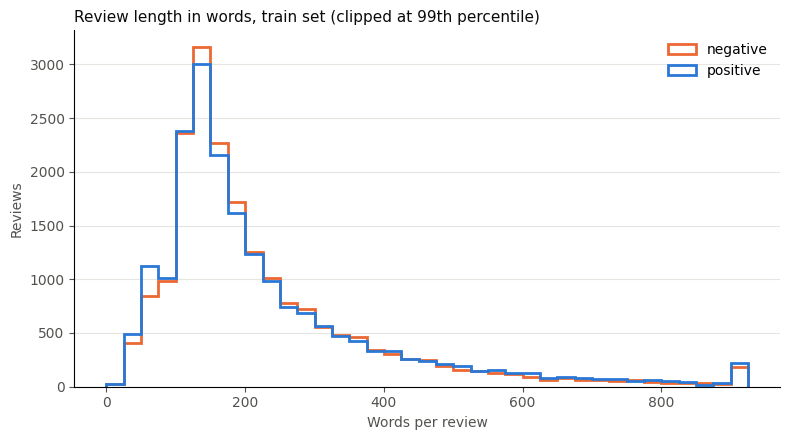

In [8]:
# Word-count distribution per class (clipped at the 99th percentile for readability)
COLORS = {'positive': '#2a78d6', 'negative': '#eb6834'}  # validated categorical slots 1-2
clip = train['n_words'].quantile(0.99)
bins = range(0, int(clip) + 25, 25)

fig, ax = plt.subplots(figsize=(8, 4.5))
for label in LABELS:
    words = train.loc[train['label'] == label, 'n_words'].clip(upper=clip)
    ax.hist(words, bins=bins, histtype='step', linewidth=2,
            color=COLORS[label], label=label)
ax.set_title('Review length in words, train set (clipped at 99th percentile)',
             loc='left', fontsize=11, color='#0b0b0b')
ax.set_xlabel('Words per review', color='#52514e')
ax.set_ylabel('Reviews', color='#52514e')
ax.legend(frameon=False)
ax.grid(axis='y', color='#e6e5e0', linewidth=0.8)
ax.set_axisbelow(True)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
ax.tick_params(colors='#52514e')
fig.tight_layout()
fig.savefig(CHART_DIR / 'eda_length_hist.png', dpi=150)
plt.show()

### 5.3 Ten random examples per class (train)
Truncated to 300 characters.

In [9]:
for label in LABELS:
    sample = train[train['label'] == label].sample(10, random_state=SEED)
    print(f'===== {label.upper()} =====')
    for i, text in enumerate(sample['text'], 1):
        snippet = text if len(text) <= 300 else text[:300] + '...'
        print(f'{i:>2}. {snippet}\n')

===== NEGATIVE =====
 1. I had to read I Know Why The Caged Birds Sing in my English class and we watched the movie after finishing it. After watching the movie, I regret seeing. It completely took away any of the impact the book had. The scenes made no sense in their sequences, the acting was horrible, and it seemed as tho...

 2. If you took all the stock elements of a Shrek movie (grumpy ogre, annoying donkey, cute kitty, obligatory dance number, etc.), put them in a blender and condensed it to 20 minutes, you'd have this mess. Painful to watch; I may have laughed once. The story and dialogue are rushed beyond comprehension...

 3. I was lying on my bed, with a really bad cold or flu or whatever. I figure maybe I'd kill some time watching some horror movies my mom bought for me a little while ago. I wish I never picked this movie! After I watched it I felt even more sick and I wanted to throw up. Afterwords(when I got better o...

 4. I watched the pilot and noticed more than a few 

## 6. Freeze the splits
A stratified sample of **exactly 300** reviews is drawn from the test pool. Every model is scored on this subset only. Only counts are printed; the reviews themselves are never displayed.

**Freeze rule.** The first run writes `train.csv.gz`, `test300.csv` and `split_manifest.json` (content hashes). Every later run recomputes the splits, checks they match the manifest, and **never overwrites** the files. If anything upstream changed (data, cleaning, seed), the run stops with an error.

In [10]:
import json
from src.data_utils import frame_hash, load_split, SPLIT_FILES, MANIFEST_PATH

test300, _ = train_test_split(
    test_pool, train_size=300, stratify=test_pool['label'], random_state=SEED
)
test300 = test300[['text', 'label']].reset_index(drop=True)
train_out = train[['text', 'label']].reset_index(drop=True)

# Sanity checks
assert len(test300) == 300
assert set(test300['text']).isdisjoint(train_out['text']), 'train/test overlap'
full_share = df['label'].value_counts(normalize=True)
for name, part in {'train': train_out, 'test300': test300}.items():
    share = part['label'].value_counts(normalize=True)
    assert (share - full_share).abs().max() < 0.01, f'{name} class ratio drifted'

pd.DataFrame({
    name: part['label'].value_counts().reindex(LABELS)
    for name, part in {'full (clean)': df, 'train': train_out, 'test300': test300}.items()
}).T.assign(total=lambda t: t.sum(axis=1))

label,negative,positive,total
full (clean),24696,24882,49578
train,19757,19905,39662
test300,149,151,300


In [11]:
splits = {'train': train_out, 'test300': test300}
manifest = {
    'source': 'IMDB 50K (data/raw/IMDB-Dataset.csv)',
    'seed': SEED,
    'test_pool_fraction': 0.2,
    'test_subset_size': 300,
    'splits': {
        name: {
            'file': SPLIT_FILES[name].name,
            'rows': len(part),
            'label_counts': part['label'].value_counts().reindex(LABELS).astype(int).to_dict(),
            'sha256': frame_hash(part),
        }
        for name, part in splits.items()
    },
}

if MANIFEST_PATH.exists():
    frozen = json.loads(MANIFEST_PATH.read_text(encoding='utf-8'))
    for name in splits:
        assert frozen['splits'][name]['sha256'] == manifest['splits'][name]['sha256'], (
            f'{name} differs from the frozen split. Do not regenerate; '
            'find what changed upstream.'
        )
    print('Splits already frozen; recomputed splits match the manifest.')
    for name, part in splits.items():  # restore only files that are missing
        if not SPLIT_FILES[name].exists():
            part.to_csv(SPLIT_FILES[name], index=False, lineterminator='\n')
            print(f'Restored missing {SPLIT_FILES[name].name}')
else:
    for name, part in splits.items():
        part.to_csv(SPLIT_FILES[name], index=False, lineterminator='\n')
    MANIFEST_PATH.write_text(json.dumps(manifest, indent=2) + '\n', encoding='utf-8')
    print('Splits written and frozen.')

# Round-trip check: what downstream notebooks will load
for name in splits:
    loaded = load_split(name)  # raises if the file doesn't match the manifest
    print(f"{SPLIT_FILES[name].name:<14} rows={len(loaded):>6,}  "
          f"sha256={manifest['splits'][name]['sha256'][:12]}...  OK")

Splits already frozen; recomputed splits match the manifest.
train.csv.gz   rows=39,662  sha256=936b52442a5c...  OK
test300.csv    rows=   300  sha256=09f011390020...  OK


## 7. EDA notes

**Cleaning**
- 50,000 raw rows -> **49,578** after cleaning. 418 exact duplicates were removed, plus 4 rows that only became duplicates once HTML was stripped. No empty texts, and no text appeared with two different labels.
- 58% of reviews (29,202) contained HTML tags, mostly `<br /><br />` paragraph breaks. These are now spaces.

**Split**
- Stratified 80/20 with seed 42: **39,662 train / 9,916 test pool**. The 300-example scoring subset is drawn from the test pool in Phase 4.

**Class balance (train)**
- negative 19,757 (49.8%), positive 19,905 (50.2%), so the classes are essentially balanced.
- A majority-class baseline therefore scores about 50% accuracy, and accuracy and macro-F1 should stay close for every model.

**Text length (train)**
- Mean 229 words (1,287 characters) and median about 171 words. The right tail is long: the 99th percentile is about 900 words and the longest review is 2,459 words.
- The length distributions of the two classes nearly overlap. Length carries almost no sentiment signal.

**What the random examples show** (these patterns feed the 30 hard cases in Phase 5)
- Plot summary is mixed in with opinion. Positive reviews often describe dark content ("sin", "condemnation", "murdered") that a lexicon reads as negative.
- Concessions and contrast: "not the best movie ever made, but it was cute", "very silly, but I've practically memorized the damn thing!"
- Sarcasm and indirect negativity: "If anyone can truly say this is a good movie, they need to be locked up."
- Comparisons to other films, where praise for film X sits inside a negative review of film Y.
- Negation, intensifiers and emphasis: "Definitely the worst", "!!!", "???".

**Implications for the three tiers**
- **VADER:** sums word scores over long, mixed texts, so plot summary and contrast clauses will likely pull scores toward the wrong pole or toward neutral.
- **Naive Bayes:** has about 40K labelled reviews to learn domain words ("drivel", "stock footage"), so it should beat VADER comfortably. It will still struggle with negation and sarcasm.
- **LLM:** a review is about 300 to 350 input tokens on average and up to about 3,000 in the tail. No truncation is needed, but length is the main cost driver.